# MetricSuite Tutorial: Inspect, Test, Compare, and Plot

`mindmap.metric.MetricSuite` manages the metrics from a study: registering them,
saving/loading, describing, plotting, and computing statistics, all from one object.
This notebook walks through a full analysis workflow on a saved study, in two parts:

- **Part 0 -- Load**: read a saved `MetricSuite` back from disk and get an overview of
  what's actually in it.
- **Part 1 -- Analyse `localization_error_hrp` at a single SNR level (5)**: the full
  single-coordinate workflow -- inspect the data, check normality, run an omnibus
  ANOVA (is there any difference at all?), then a pairwise comparison with
  multiple-comparison correction (which pairs differ?), each step plotted.
- **Part 2 -- Analyse `correlation_pp` across the whole SNR sweep**: the
  coordinate-resolved counterpart -- a cluster-permutation test answers *where along
  the sweep* two methods differ, not just whether they differ overall.

Data: `noisesweep/`, a `MetricSuite` saved next to this notebook -- the noise/SNR
sweep study built by `tutorials/analysis/inverse/inverse-noisesweep.ipynb` (5 inverse
methods x 6 SNR levels x 8 regions x 5 repetitions). See that notebook for how the
study was generated and why each metric is tagged with `method`, `snr`, *and*
`region`.

## 📦 - Part 0: Load

`MetricSuite.peek(folder)` reads only `meta.json` -- cheap even for large studies,
useful for a quick look before committing to a full load (e.g. when scanning many
per-subject folders). `MetricSuite.load(folder)` reads the whole thing back (a
`data.npz` + `meta.json` pair written by `.save()`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import mindmap as mm

COLORS = {
    "wcset":   "#2a78d6",  # blue
    "cset":    "#1baf7a",  # aqua
    "sloreta": "#008300",  # green
    "dspm":    "#4a3aa7",  # violet
    "mne":     "#e34948",  # red
}

print(mm.metric.MetricSuite.peek("noisesweep"))

{'name': 'Noise/SNR sweep simf10-noisesweep', 'metadata': {}, 'saved_at': '2026-07-22T13:32:04.279576', 'n_entries': 6000, 'metrics': ['ap_hrp', 'ap_pp', 'correlation_hrp', 'correlation_pp', 'localization_error_hrp']}


In [2]:
suite = mm.metric.MetricSuite.load("noisesweep")
suite.name

'Noise/SNR sweep simf10-noisesweep'

### Summarizing the suite's structure

Before computing anything, `.describe()` answers "what's actually in here" -- every
registered metric, and for each, which coords it carries: `"categorical"` (with how
many distinct values) or `"numerical"` (with its range). A quick structural map of
the study before reaching for `.summary()` (the numbers) or `.to_df()` (the raw
table).

In [3]:
suite.describe()

,Metric,Coord,Kind,N unique,Detail
0,ap_hrp,method,categorical,5,"cset, dspm, mne, sloreta, wcset"
1,ap_hrp,snr,numerical,6,"[1, 50]"
2,ap_hrp,region,categorical,8,"ctx-lh-lateraloccipital_1, ctx-lh-middletempor..."
3,ap_hrp,Label,categorical,5,"cset, dspm, mne, sloreta, wcset"
4,ap_pp,method,categorical,5,"cset, dspm, mne, sloreta, wcset"
5,ap_pp,snr,numerical,6,"[1, 50]"
6,ap_pp,region,categorical,8,"ctx-lh-lateraloccipital_1, ctx-lh-middletempor..."
7,ap_pp,Label,categorical,5,"cset, dspm, mne, sloreta, wcset"
8,correlation_hrp,method,categorical,5,"cset, dspm, mne, sloreta, wcset"
9,correlation_hrp,snr,numerical,6,"[1, 50]"


Every metric here carries the same three coords: `method` (== `Label`, the
wCSET/CSET/dSPM/MNE/sLORETA method -- duplicated under both names, an artifact of
this particular saved study's history), `snr` (numerical, 6 levels), and `region`
(the brain region a run's source was simulated in, categorical, 8 options) --
`region` is what makes both the pairwise and cluster-permutation tests below valid,
since repetitions aren't matched across SNR levels but the same physical region is.

## 🔬 - Part 1: Analysing `localization_error_hrp` at SNR = 5

A single SNR level collapses away the sweep entirely, leaving a simple "does method
matter" question -- the right shape for the omnibus-then-pairwise workflow. SNR = 5
sits in the middle of the sweep, where methods are the least likely to all agree (too
easy at high SNR, too hard at low SNR).

### Inspect the data

`.summary(metric, group_by=..., filters=...)` gives a quick per-group mean/std/count
-- a sanity check before testing anything.

In [4]:
suite.summary("localization_error_hrp", group_by="Label", filters={"snr": 5})

,Label,mean,std,count
0,cset,24.536726,22.758685,40
1,dspm,14.402679,7.552338,40
2,mne,62.988901,37.191292,40
3,sloreta,39.515989,36.471559,40
4,wcset,7.325993,10.470874,40


### Checking normality

`localization_error` is a distance (always positive, often right-skewed) -- worth
checking before leaning on a test that assumes normality. `.stat.normality_test`
runs a Shapiro-Wilk test per group (the null hypothesis is normality, so a *small*
p-value is evidence *against* it -- `significant` here means "significantly
non-normal").

In [5]:
norm = suite.stat.normality_test("localization_error_hrp", group_by="Label", filters={"snr": 5})
norm.table

,group,n,statistic,p_value,p_corrected,significant
0,cset,40,0.878755,4.872618e-04,8.121030e-04,True
1,dspm,40,0.922125,8.987322e-03,1.123415e-02,True
2,mne,40,0.961192,1.839431e-01,1.839431e-01,False
3,sloreta,40,0.854081,1.131868e-04,2.829669e-04,True
4,wcset,40,0.634658,9.602546e-09,4.801273e-08,True


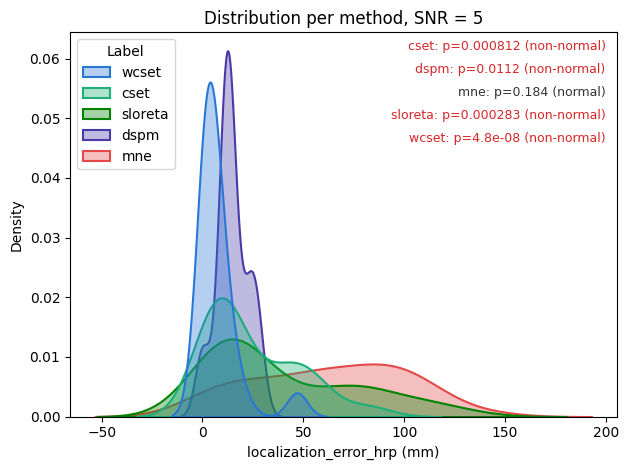

In [6]:
fig, ax = suite.plot.normality_test(norm, palette=COLORS)
ax.set_xlabel("localization_error_hrp (mm)")
ax.set_title("Distribution per method, SNR = 5")
fig.tight_layout()

Most methods come back significantly non-normal here (`wcset` most strongly of all,
`mne` the one exception) -- exactly the skewed-distance shape you'd expect, and the
reason `.stat.wilcoxon` (no normality assumption) is the right pick below, not
`.stat.paired_ttest`.

### Pre-stat: is there any difference at all?

Before chasing pairwise comparisons, `.stat.anova` asks the omnibus question first:
do these five methods differ *at all* on this metric, at this SNR? Only worth
following up with pairwise tests (below) if this comes back significant -- the
standard "omnibus, then post-hoc" two-step, which avoids inflating the false-positive
rate that jumping straight to every pairwise test would risk. Default test is
`"friedman"` (non-parametric, matching the same non-normality concern as above).

In [7]:
anova = suite.stat.anova("localization_error_hrp", group_by="Label", pairing_col="region", filters={"snr": 5})
anova

AnovaResult(metric='localization_error_hrp', test='friedman', groups=('cset', 'dspm', 'mne', 'sloreta', 'wcset')): p=4.586e-05*, kendalls_w=0.788, n=8, k=5

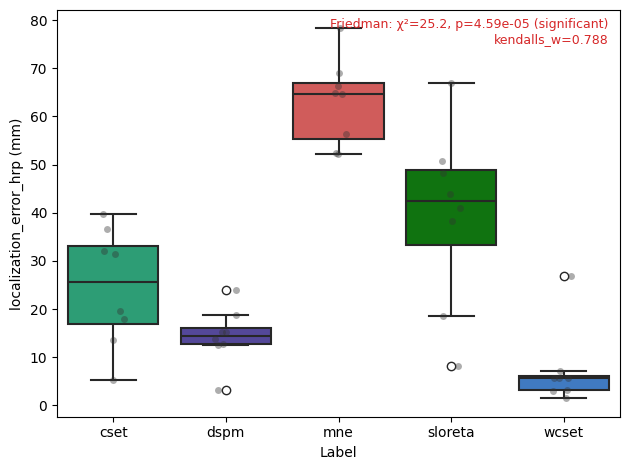

In [8]:
fig, ax = suite.plot.anova(anova, palette=COLORS)
ax.set_ylabel("localization_error_hrp (mm)")
fig.tight_layout()

A large, significant effect (Kendall's W = 0.79) -- worth chasing which pairs
actually differ.

### Pairwise comparison, FDR-corrected

`.stat.wilcoxon` runs a paired Wilcoxon test of each competitor against
`reference`, matched by `region` (`pairing_col`), with the resulting p-values
corrected together as one family (`correction="fdr_bh"` by default) -- exactly the
post-hoc step the omnibus result above says is worth taking.

In [9]:
cmp = suite.stat.wilcoxon(
    "localization_error_hrp", group_by="Label",
    comparisons=suite.stat.build_comparisons("wcset", ["cset", "dspm", "mne", "sloreta"]),
    pairing_col="region",
    filters={"snr": 5},
)
cmp.table

,group_a,group_b,n_pairs,n_a,n_b,statistic,p_value,effect_size,effect_size_type,n_eff,p_corrected,significant
0,wcset,cset,8,8,8,3.0,0.039062,-0.75,rank_biserial,NaN,0.052083,False
1,wcset,dspm,8,8,8,8.0,0.195312,-0.75,rank_biserial,NaN,0.195312,False
2,wcset,mne,8,8,8,0.0,0.007812,-1.00,rank_biserial,NaN,0.015625,True
3,wcset,sloreta,8,8,8,0.0,0.007812,-1.00,rank_biserial,NaN,0.015625,True


wCSET is significantly better than `mne` and `sloreta` here, but not distinguishable
from `cset`/`dspm` once corrected -- the omnibus test only told us *some* pair
differs, not *which*; this is the "which" answer.

### Plot: annotated box plot

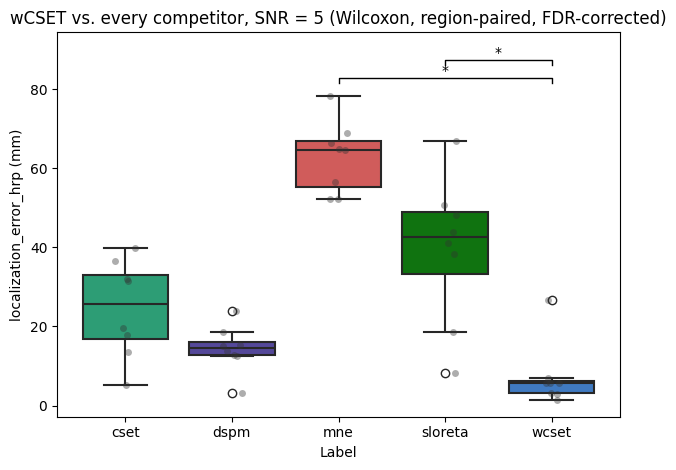

In [10]:
fig, ax = suite.plot.group_comparison(cmp, palette=COLORS)
ax.set_ylabel("localization_error_hrp (mm)")
ax.set_title("wCSET vs. every competitor, SNR = 5 (Wilcoxon, region-paired, FDR-corrected)")
fig.tight_layout()

## 🌊 - Part 2: `correlation_pp` across the whole SNR sweep

Part 1 collapsed the sweep to ask "does it differ overall". The complementary
question -- *where along the sweep* two methods differ -- needs a test that's
resolved along the coordinate itself: `.stat.cluster_permutation`, a
cluster-permutation test between two groups at a time, region as the
repeated-measures subject and SNR as the swept coordinate (the standard Maris &
Oostenveld design).

**Is there a coordinate-resolved counterpart to the ANOVA pre-stat from Part 1?**
Not currently -- `cluster_permutation` wraps a *one-sample, sign-flip* test
(`mne.stats.permutation_cluster_1samp_test`) built for exactly two matched groups;
extending it to an omnibus, cluster-corrected F-test across three or more groups
would need a genuinely different permutation scheme (shuffling group labels rather
than sign-flipping a paired difference) and isn't built here yet. In the meantime,
the plain `.stat.anova` from Part 1 -- run on this metric collapsed over the whole
sweep, ignoring *where* -- is a reasonable cheap gate: if it comes back
non-significant, there's little reason to spend the permutation budget on multiple
per-competitor cluster tests.

In [11]:
anova_pp = suite.stat.anova("correlation_pp", group_by="Label", pairing_col="region")
anova_pp

AnovaResult(metric='correlation_pp', test='friedman', groups=('cset', 'dspm', 'mne', 'sloreta', 'wcset')): p=2.753e-05*, kendalls_w=0.822, n=8, k=5

Significant, so the cluster-permutation tests below are worth running.

### Every competitor vs. wCSET

- `pairing_col="region"`: repeated-measures unit. Repetitions can't serve this role
  -- each `(region, snr, repetition)` run drew its own independent seed (including
  the signal-jitter, not just the noise), so reps aren't matched across SNR levels.
  Region is: it's the same physical region at every SNR level.
- `coord_order=[50, 20, 10, 5, 2, 1]`: explicit descending order, since "decreasing
  SNR" is the meaningful contiguity direction (increasing noise), not numeric
  ascending order.
- `higher_is_better=True` (default): `correlation_pp` is better when higher, so a
  positive result means "wCSET wins".

Requesting more than one competitor in a single `cluster_permutation` call pools
every competitor's cluster p-values into one family and FDR-corrects across it, then
`plot.cluster_permutation` auto-switches to a compact multi-competitor overlay:
solid line + filled marker where a competitor is significantly worse than wCSET,
dashed + open marker where it isn't (deliberately not opacity-encoded -- solid/dashed
+ filled/open survives grayscale printing and low-vision viewing better than two
alpha levels on a colored line). Each point also carries a thin IQR whisker
(`show_spread=True`, the default) -- good practice to show uncertainty alongside a
significance verdict, not just the verdict.

In [12]:
snr_order = [50, 20, 10, 5, 2, 1]

result_all = suite.stat.cluster_permutation(
    metric="correlation_pp", coord="snr", group_by="Label",
    comparisons=suite.stat.build_comparisons("wcset", ["cset", "dspm", "mne", "sloreta"]),
    pairing_col="region", coord_order=snr_order,
    n_permutations=3000, seed=0,
)
pd.concat(
    [cl.assign(competitor=b) for (a, b), cl in result_all.clusters_by_pair.items()],
    ignore_index=True,
)

,snr_start,snr_end,mass,sign,p_value,significant,effect_size,effect_size_type,p_corrected,competitor
0,50,10,15.993957,1,0.015625,True,1.774428,cohens_dz,0.015625,cset
1,2,1,17.005922,1,0.015625,True,2.733856,cohens_dz,0.015625,cset
2,50,1,74.013149,1,0.007812,True,4.455655,cohens_dz,0.013021,dspm
3,50,1,98.974994,1,0.007812,True,6.057395,cohens_dz,0.013021,mne
4,50,1,77.809419,1,0.007812,True,4.692023,cohens_dz,0.013021,sloreta


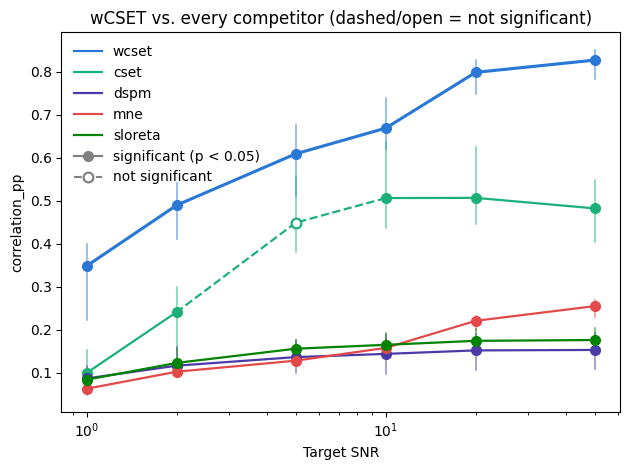

In [13]:
fig, ax = suite.plot.cluster_permutation(result_all, marker="o", colors=COLORS)
ax.set_xscale("log")
ax.set_xlabel("Target SNR")
ax.set_ylabel("correlation_pp")
ax.set_title("wCSET vs. every competitor (dashed/open = not significant)")
fig.tight_layout()

## Wrap-up

- `MetricSuite.peek("noisesweep")` / `.load("noisesweep")` -- cheap look, then full
  read of a saved study.
- `suite.describe()` -- structural overview: every metric, its coords, and whether
  each is categorical (n options) or numerical (range).
- `suite.summary(metric, group_by=..., filters=...)` -- quick per-group mean/std/count.
- `suite.stat.normality_test(metric, group_by=...)` + `suite.plot.normality_test(result)`
  -- per-group Shapiro-Wilk test, annotated onto a distribution plot.
- `suite.stat.anova(metric, group_by=..., pairing_col=...)` + `suite.plot.anova(result)`
  -- omnibus "is there any difference at all", the pre-stat gate before pairwise
  testing.
- `suite.stat.wilcoxon(metric, group_by=..., comparisons=..., pairing_col=...)` +
  `suite.plot.group_comparison(result)` -- pairwise paired Wilcoxon test,
  FDR-corrected across competitors, annotated box plot.
- `suite.stat.cluster_permutation(metric, coord=..., group_by=..., comparisons=..., pairing_col=...)`
  + `suite.plot.cluster_permutation(result)` -- *where along the sweep* a pair (or
  every competitor at once) differs, with region as the permutation subject.

See `mindmap/metric/base.py` (`describe`, `summary`, `to_df`), `mindmap/metric/stat.py`
(`wilcoxon`/`ttest`/`mannwhitneyu`/`paired_ttest`/`ttest_ess`, `cluster_permutation`, `normality_test`, `anova`), and
`mindmap/metric/plot.py` (the matching `suite.plot.*` views) for the full
`MetricSuite` API, and `tutorials/analysis/inverse/inverse-noisesweep.ipynb` for how
this study's data was generated and registered.